In [1]:
import pandas as pd

df = pd.read_excel("/content/employee_attrition_hr_2026.xlsx")

df.head()

,employee_id,age,gender,marital_status,education_level,department,job_role,job_level,monthly_income,stock_option_level,...,training_hours,manager_support_score,burnout_score,engagement_score,work_life_balance_score,performance_rating,last_review_score,uses_ai_tools_at_work,perceived_ai_job_risk,attrition
0,1001,37,Male,Divorced,Masters,Engineering,Engineering Manager,3,7365,0,...,17,9.4,1.0,9.7,7.7,3,8.3,True,4.8,No
1,1002,24,Female,Married,Bachelors,Finance,Finance Manager,2,4746,2,...,21,4.2,1.9,5.4,7.8,3,8.0,True,2.9,Yes
2,1003,24,Female,Single,Bachelors,Marketing,Marketing Specialist,1,2740,2,...,22,7.5,5.3,6.5,7.0,4,9.5,True,7.2,No
3,1004,44,Male,Single,Bachelors,Sales,Sales Manager,4,7334,1,...,21,8.7,4.3,7.3,3.5,4,7.9,False,5.2,No
4,1005,37,Female,Divorced,Bachelors,Sales,Sales Development Rep,3,9096,0,...,20,7.5,2.3,7.0,7.2,4,8.5,False,6.4,No


In [2]:
df.shape, df.isnull().sum().sum(), df.columns.tolist()

((5000, 29),
 np.int64(0),
 ['employee_id',
  'age',
  'gender',
  'marital_status',
  'education_level',
  'department',
  'job_role',
  'job_level',
  'monthly_income',
  'stock_option_level',
  'salary_hike_pct',
  'years_at_company',
  'total_working_years',
  'years_since_promotion',
  'num_prior_companies',
  'work_mode',
  'commute_minutes',
  'overtime_hours_per_week',
  'business_travel_days_per_year',
  'training_hours',
  'manager_support_score',
  'burnout_score',
  'engagement_score',
  'work_life_balance_score',
  'performance_rating',
  'last_review_score',
  'uses_ai_tools_at_work',
  'perceived_ai_job_risk',
  'attrition'])

In [3]:
X = df.drop(columns=["employee_id", "attrition"])
y = df["attrition"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (5000, 27)
Target: (5000,)


In [4]:
y = y.map({"No": 0, "Yes": 1})

print(y.value_counts())

attrition
0    4105
1     895
Name: count, dtype: int64


In [5]:
categorical_cols = X.select_dtypes(include=["object", "bool"]).columns.tolist()
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Categorical:", categorical_cols)
print("Numerical:", numerical_cols)

Categorical: ['gender', 'marital_status', 'education_level', 'department', 'job_role', 'work_mode', 'uses_ai_tools_at_work']
Numerical: ['age', 'job_level', 'monthly_income', 'stock_option_level', 'salary_hike_pct', 'years_at_company', 'total_working_years', 'years_since_promotion', 'num_prior_companies', 'commute_minutes', 'overtime_hours_per_week', 'business_travel_days_per_year', 'training_hours', 'manager_support_score', 'burnout_score', 'engagement_score', 'work_life_balance_score', 'performance_rating', 'last_review_score', 'perceived_ai_job_risk']


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print(X_train.shape, X_val.shape, X_test.shape)

(3500, 27) (750, 27) (750, 27)


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

print(X_train.shape)

(3500, 69)


In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

model = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(32, activation="relu"),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,593 (25.75 KB)

 Trainable params: 6,593 (25.75 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [10]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7803 - loss: 0.4968 - val_accuracy: 0.8213 - val_loss: 0.4002
Epoch 2/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8206 - loss: 0.4285 - val_accuracy: 0.8333 - val_loss: 0.3889
Epoch 3/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8257 - loss: 0.4172 - val_accuracy: 0.8320 - val_loss: 0.3836
Epoch 4/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8257 - loss: 0.4044 - val_accuracy: 0.8347 - val_loss: 0.3835
Epoch 5/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8269 - loss: 0.4024 - val_accuracy: 0.8320 - val_loss: 0.3796
Epoch 6/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8303 - loss: 0.3997 - val_accuracy: 0.8333 - val_loss: 0.3791
Epoch 7/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8303 - loss: 0.3958 - val_accuracy: 0.8333 - val_loss: 0.3813
Epoch 8/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8291 - loss: 0.3960 - val_accu

In [11]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

Test Accuracy: 0.8346666693687439
Test Loss: 0.3902985453605652


In [12]:
y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(y_prob[:5])

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
[0.04804853 0.05925978 0.00346525 0.18984021 0.26777512]


In [13]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Stay", "Leave"]
))

              precision    recall  f1-score   support

        Stay       0.84      0.98      0.91       616
       Leave       0.66      0.16      0.25       134

    accuracy                           0.83       750
   macro avg       0.75      0.57      0.58       750
weighted avg       0.81      0.83      0.79       750



In [14]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[605  11]
 [113  21]]


In [15]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(weights))

print(class_weights)

{0: np.float64(0.6091193873999304), 1: np.float64(2.7910685805422646)}


In [16]:
weighted_model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

weighted_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

weighted_history = weighted_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5531 - loss: 0.6519 - val_accuracy: 0.7213 - val_loss: 0.5713
Epoch 2/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6891 - loss: 0.5980 - val_accuracy: 0.7333 - val_loss: 0.5330
Epoch 3/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6817 - loss: 0.5884 - val_accuracy: 0.7520 - val_loss: 0.5135
Epoch 4/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6971 - loss: 0.5838 - val_accuracy: 0.7240 - val_loss: 0.5397
Epoch 5/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7009 - loss: 0.5730 - val_accuracy: 0.7120 - val_loss: 0.5434
Epoch 6/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7009 - loss: 0.5636 - val_accuracy: 0.7280 - val_loss: 0.5246
Epoch 7/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7086 - loss: 0.5661 - val_accuracy: 0.7307 - val_loss: 0.5271
Epoch 8/100
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7149 - loss: 0.5546 - val_accu

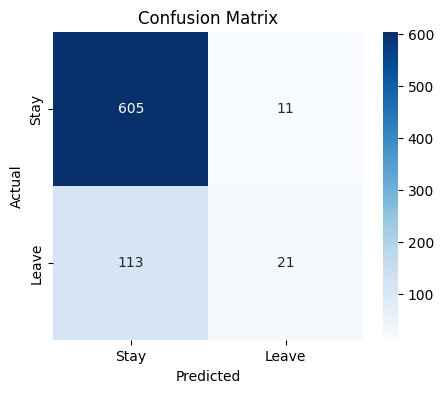

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay", "Leave"],
    yticklabels=["Stay", "Leave"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [18]:
y_prob_weighted = weighted_model.predict(X_test).ravel()
y_pred_weighted = (y_prob_weighted >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred_weighted,
    target_names=["Stay", "Leave"]
))

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
              precision    recall  f1-score   support

        Stay       0.91      0.71      0.80       616
       Leave       0.34      0.68      0.45       134

    accuracy                           0.71       750
   macro avg       0.63      0.70      0.63       750
weighted avg       0.81      0.71      0.74       750



In [19]:
y_prob = y_prob_weighted
y_pred = y_pred_weighted

In [20]:
def risk_level(probability):
    if probability < 0.30:
        return "Low"
    elif probability < 0.60:
        return "Medium"
    else:
        return "High"

risk_levels = [risk_level(p) for p in y_prob]

print(risk_levels[:10])

['Low', 'Medium', 'Low', 'Medium', 'Medium', 'Medium', 'High', 'High', 'Medium', 'Medium']


In [21]:
!pip install shap -q

In [22]:
import shap

explainer = shap.Explainer(weighted_model, X_train)

In [23]:
shap_values = explainer(X_test)

PermutationExplainer explainer: 751it [01:19,  8.63it/s]


In [24]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['num__age' 'num__job_level' 'num__monthly_income'
 'num__stock_option_level' 'num__salary_hike_pct' 'num__years_at_company'
 'num__total_working_years' 'num__years_since_promotion'
 'num__num_prior_companies' 'num__commute_minutes'
 'num__overtime_hours_per_week' 'num__business_travel_days_per_year'
 'num__training_hours' 'num__manager_support_score' 'num__burnout_score'
 'num__engagement_score' 'num__work_life_balance_score'
 'num__performance_rating' 'num__last_review_score'
 'num__perceived_ai_job_risk' 'cat__gender_Female' 'cat__gender_Male'
 'cat__gender_Non-binary' 'cat__gender_Prefer not to say'
 'cat__marital_status_Divorced' 'cat__marital_status_Married'
 'cat__marital_status_Single' 'cat__education_level_Bachelors'
 'cat__education_level_High School' 'cat__education_level_Masters'
 'cat__education_level_PhD' 'cat__department_Customer Support'
 'cat__department_Engineering' 'cat__department_Finance'
 'cat__department_Human Resources' 'cat__department_Marketing'
 'cat__departm

/tmp/ipykernel_1103/2493234127.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


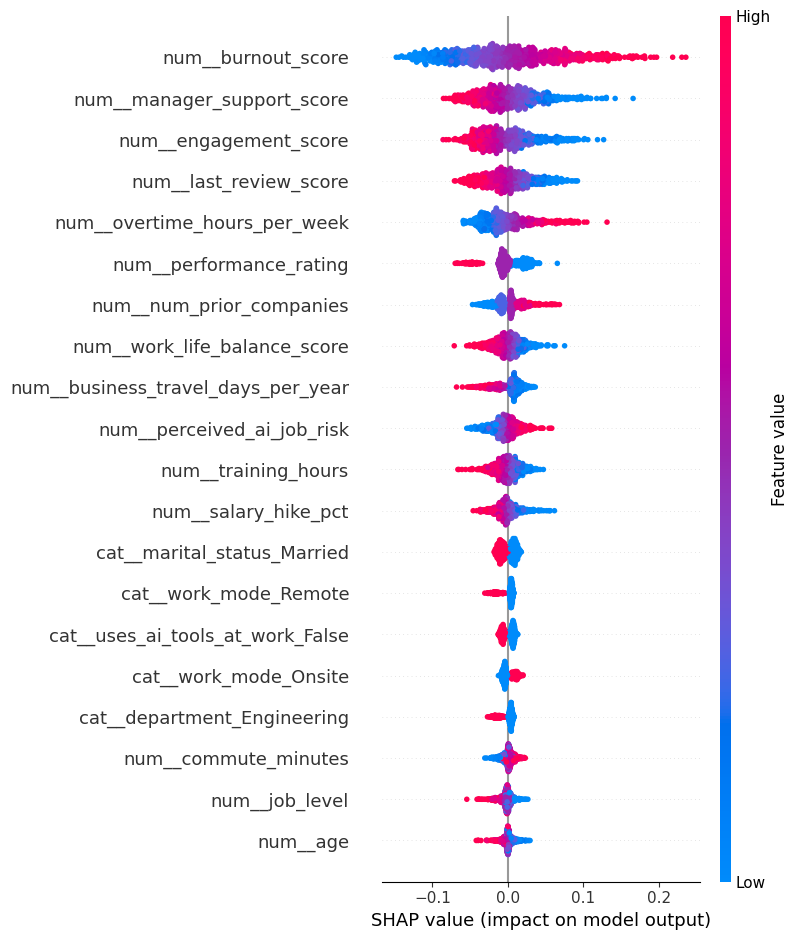

In [25]:
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=list(feature_names)
)

In [26]:
employee_index = 0

employee = X_test[employee_index:employee_index+1]
employee_probability = y_prob[employee_index]

print("Attrition Probability:", employee_probability)
print("Risk Level:", risk_level(employee_probability))

Attrition Probability: 0.20908044
Risk Level: Low


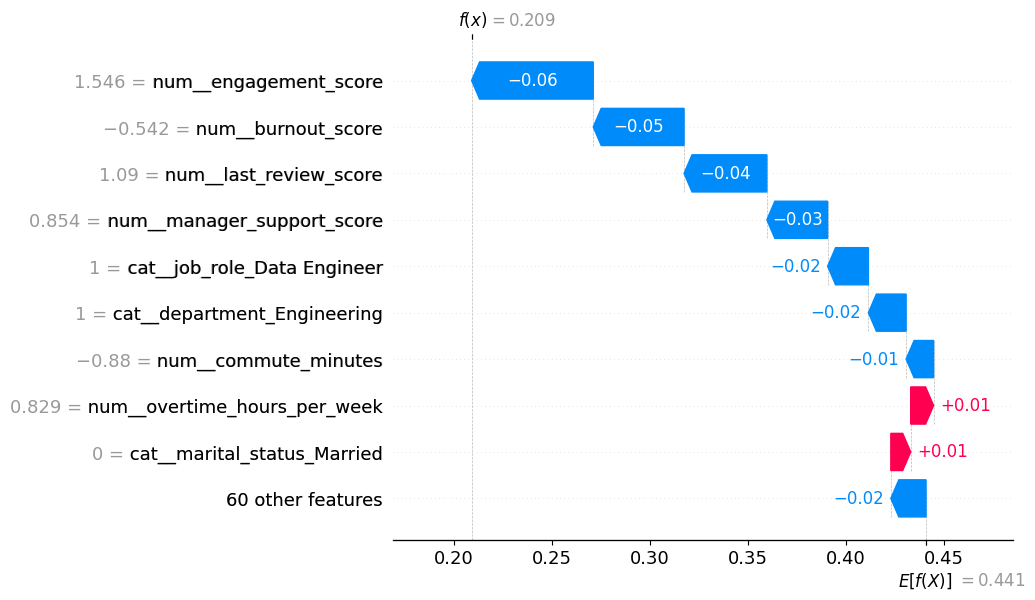

In [27]:
employee_index = 0

individual_shap = shap_values[employee_index]

individual_shap.feature_names = list(feature_names)

shap.plots.waterfall(individual_shap, max_display=10)

In [28]:
from sklearn.model_selection import train_test_split

X_original = df.drop(columns=["employee_id", "attrition"])
y_original = df["attrition"].map({"No": 0, "Yes": 1})

X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X_original, y_original,
    test_size=0.30,
    random_state=42,
    stratify=y_original
)

X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw,
    test_size=0.50,
    random_state=42,
    stratify=y_temp_raw
)

employee_raw = X_test_raw.iloc[employee_index].copy()

print(employee_raw)

age                                         40
gender                                  Female
marital_status                        Divorced
education_level                      Bachelors
department                         Engineering
job_role                         Data Engineer
job_level                                    3
monthly_income                            8481
stock_option_level                           0
salary_hike_pct                           11.8
years_at_company                           9.4
total_working_years                       11.6
years_since_promotion                      0.9
num_prior_companies                          2
work_mode                               Hybrid
commute_minutes                             14
overtime_hours_per_week                   10.5
business_travel_days_per_year                7
training_hours                              11
manager_support_score                      8.2
burnout_score                              3.2
engagement_sc

In [29]:
employee_whatif = employee_raw.copy()

employee_whatif["overtime_hours_per_week"] = 5

print("Original overtime:", employee_raw["overtime_hours_per_week"])
print("What-If overtime:", employee_whatif["overtime_hours_per_week"])

Original overtime: 10.5
What-If overtime: 5


In [30]:
id="r3v6x2"
employee_whatif_processed = preprocessor.transform(
    pd.DataFrame([employee_whatif])
)

whatif_probability = weighted_model.predict(
    employee_whatif_processed,
    verbose=0
)[0][0]

print("Original Risk:", employee_probability)
print("What-If Risk:", whatif_probability)

Original Risk: 0.20908044
What-If Risk: 0.2110019


In [31]:
risk_change = whatif_probability - employee_probability

print("Original Risk:", round(employee_probability * 100, 2), "%")
print("What-If Risk:", round(whatif_probability * 100, 2), "%")
print("Change:", round(risk_change * 100, 2), "percentage points")

Original Risk: 20.91 %
What-If Risk: 21.1 %
Change: 0.19 percentage points


In [32]:
employee_whatif2 = employee_raw.copy()

employee_whatif2["engagement_score"] = 9.5

employee_whatif2_processed = preprocessor.transform(
    pd.DataFrame([employee_whatif2])
)

whatif_probability2 = weighted_model.predict(
    employee_whatif2_processed,
    verbose=0
)[0][0]

print("Original Risk:", round(employee_probability * 100, 2), "%")
print("What-If Risk:", round(whatif_probability2 * 100, 2), "%")
print(
    "Change:",
    round((whatif_probability2 - employee_probability) * 100, 2),
    "percentage points"
)

Original Risk: 20.91 %
What-If Risk: 19.78 %
Change: -1.13 percentage points


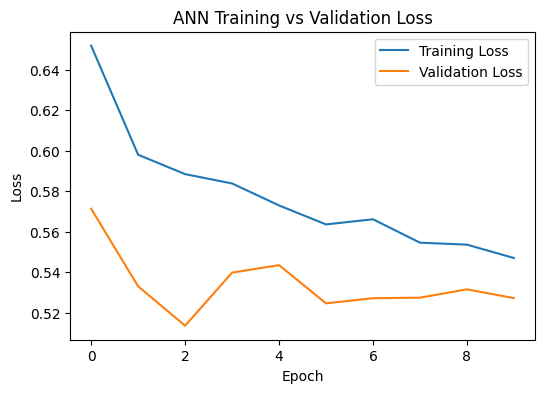

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(weighted_history.history["loss"], label="Training Loss")
plt.plot(weighted_history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training vs Validation Loss")
plt.legend()
plt.show()

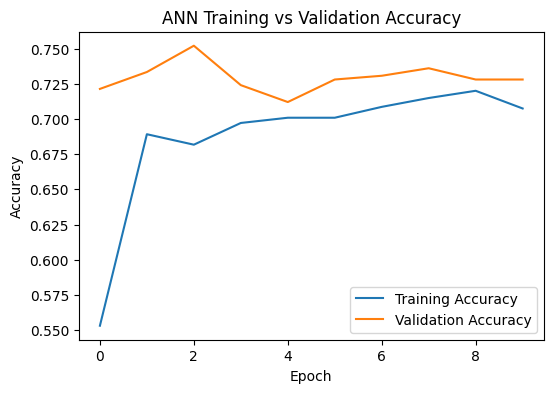

In [34]:
plt.figure(figsize=(6, 4))

plt.plot(weighted_history.history["accuracy"], label="Training Accuracy")
plt.plot(weighted_history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN Training vs Validation Accuracy")
plt.legend()
plt.show()

In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy :", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred) * 100, 2), "%")
print("Recall   :", round(recall_score(y_test, y_pred) * 100, 2), "%")
print("F1 Score :", round(f1_score(y_test, y_pred) * 100, 2), "%")

Accuracy : 70.67 %
Precision: 33.96 %
Recall   : 67.91 %
F1 Score : 45.27 %


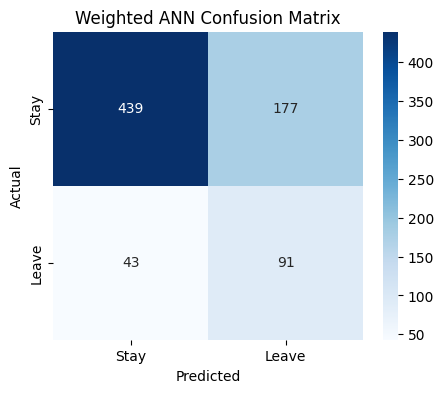

In [36]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay", "Leave"],
    yticklabels=["Stay", "Leave"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Weighted ANN Confusion Matrix")

plt.show()

In [37]:
from collections import Counter

risk_counts = Counter(risk_levels)

print("Low Risk:", risk_counts["Low"])
print("Medium Risk:", risk_counts["Medium"])
print("High Risk:", risk_counts["High"])

Low Risk: 187
Medium Risk: 416
High Risk: 147


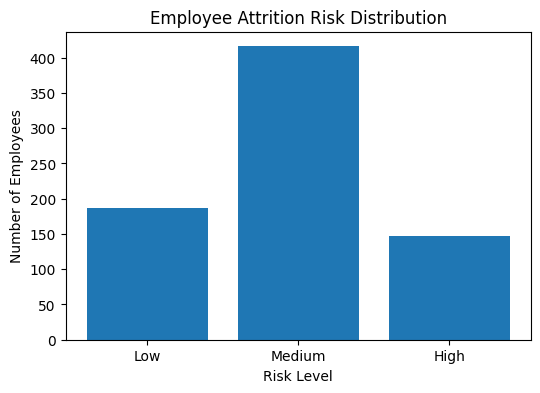

In [38]:
plt.figure(figsize=(6, 4))

plt.bar(
    risk_counts.keys(),
    risk_counts.values()
)

plt.xlabel("Risk Level")
plt.ylabel("Number of Employees")
plt.title("Employee Attrition Risk Distribution")

plt.show()

In [39]:
results = {
    "Accuracy": round(accuracy_score(y_test, y_pred) * 100, 2),
    "Precision": round(precision_score(y_test, y_pred) * 100, 2),
    "Recall": round(recall_score(y_test, y_pred) * 100, 2),
    "F1 Score": round(f1_score(y_test, y_pred) * 100, 2),
    "Low Risk": risk_counts["Low"],
    "Medium Risk": risk_counts["Medium"],
    "High Risk": risk_counts["High"]
}

results_df = pd.DataFrame([results])

results_df

,Accuracy,Precision,Recall,F1 Score,Low Risk,Medium Risk,High Risk
0,70.67,33.96,67.91,45.27,187,416,147
